# Does a time crystal make a good reservoir? A 6-spin Floquet quantum reservoir on real time series

**Qiskit Fall Fest 2026 — Track 2 entry.**

> **Everything in this notebook is a classical simulation — no quantum hardware used.**
> The 6-spin reservoir is simulated exactly with NumPy density matrices (64 × 64). One reservoir step is cross-checked
> against Qiskit Aer's density-matrix simulator in Section 3. Nothing here is a claim of quantum advantage.

Run time: the live cells take well under a minute on a laptop. Heavy experiments were run once by
`python -m qreservoir.experiments` and saved as JSON in `artifacts/`. Section 6 only reads those files.

## 1. Question and answer

**Question.** We use a disordered kicked-Ising spin chain as the reservoir. Its kick angle θ moves it between dynamical
regimes: weak kicks (θ small), strong scrambling (θ ≈ π/2), and a discrete time crystal (DTC) near θ ≈ π. Which regime
makes the best reservoir? Does that answer hold up against classical models given the same features, the same data
splits and the same readout?

**Answer (from the data below).**

1. **The time-crystal regime gives close to the least memory.** Near θ ≈ π the chain locks into period-doubled
   oscillation. It then carries almost nothing about past inputs: its short-term memory drops toward the floor set by
   the no-interaction (J = 0) control, which barely remembers anything beyond the current input. Across the scan,
   memory is *anti*-correlated with time-crystal order.
2. **The scrambling regime (θ ≈ 0.4–0.6 π, J = 0.4) has the most memory.** It is comparable to a classical echo-state
   network (ESN) with the same number of readout features (11), and below a plain 11-lag linear buffer.
3. **On real data the classical models win.** On yearly sunspots and monthly Mauna Loa CO₂ changes, a linear
   autoregressive (AR) model is best, the ESN is second, and the quantum reservoir is third. Diebold–Mariano tests make
   AR's lead significant for most seeds.
4. **The interactions do matter.** On CO₂ the interacting quantum reservoir clearly beats its own no-interaction
   (J = 0) control, so the gain comes from the many-body dynamics, not from the single-qubit input encoding.
5. **Finite shots erase the scrambling memory.** With realistic shot counts, the memory advantage of the scrambling
   regime mostly disappears, and the hardware restart cost of reading out every step is large.

All numbers behind these statements are printed by the code cells below. None are typed by hand.

In [1]:
import json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from qreservoir.reservoir import FloquetReservoir, EchoStateNetwork, lagged
from qreservoir.tasks import capacities, diebold_mariano
from qreservoir.circuit import step_circuit

LABEL = "classical simulation — no quantum hardware used"
ROOT = Path.cwd() if (Path.cwd() / "artifacts").exists() else Path.cwd().parent
ART, FIG = ROOT / "artifacts", ROOT / "figures"
load = lambda name: json.loads((ART / name).read_text())
e1, e2, e3, summary = load("e1_phase_scan.json"), load("e2_forecast.json"), load("e3_shots_noise.json"), load("summary.json")
pd.set_option("display.precision", 3)
T0 = time.time()
print("Artifacts from:", ART)
print("Saved statement:", summary["statement"])

Artifacts from: /Users/wyatt/dev/floquet-reservoir/artifacts
Saved statement: All results: classical simulation on a laptop (NumPy density matrices; reservoir step verified against Qiskit Aer). No quantum hardware used.


In [2]:
# Headline numbers, read from artifacts/summary.json (classical simulation — no quantum hardware used)
m = summary["memory"]
print(f"[{LABEL}]")
print(f"Memory capacity MC (6 spins, J=0.4, 2 cycles/step, mean of 5 seeds):")
print(f"  best theta = {m['best_theta_over_pi']:.2f} pi  ->  MC = {m['best_MC']:.2f}")
print(f"  time-crystal theta = {m['dtc_theta_over_pi']:.2f} pi  ->  MC = {m['dtc_MC']:.2f}  (DTC order {m['dtc_order_at_0.95']:.2f})")
print(f"  J = 0 control, best over theta: MC = {m['J0_MC_max']:.2f}")
print(f"  ESN (11 nodes) range: {m['esn_MC_range'][0]:.2f} – {m['esn_MC_range'][1]:.2f};  11-lag linear buffer: {m['lags11_MC']:.2f}")
print(f"  correlation(MC, DTC order) over the J>0 scan: {m['corr_MC_vs_dtc_order']:+.2f}")
print()
for s, d in summary["forecast"].items():
    print(f"{s}: test NMSE  AR(p={d['ar_p']}) {d['ar_test_nmse']:.3f} | ESN median {d['esn']['median_test_nmse']:.3f} | "
          f"quantum median {d['quantum_reservoir']['median_test_nmse']:.3f} | quantum J=0 median {d['quantum_reservoir_J0']['median_test_nmse']:.3f} | "
          f"persistence {d['persistence_test_nmse']:.3f}")
print()
for th, d in summary["shots_MC"].items():
    print(f"theta={th} pi: MC exact {d['exact']:.2f} | 10k shots {d['10000']:.2f} | 1k shots {d['1000']:.2f} | 100 shots {d['100']:.2f}")

[classical simulation — no quantum hardware used]
Memory capacity MC (6 spins, J=0.4, 2 cycles/step, mean of 5 seeds):
  best theta = 0.45 pi  ->  MC = 5.75
  time-crystal theta = 0.95 pi  ->  MC = 1.32  (DTC order 0.97)
  J = 0 control, best over theta: MC = 1.07
  ESN (11 nodes) range: 5.31 – 7.82;  11-lag linear buffer: 11.00
  correlation(MC, DTC order) over the J>0 scan: -0.51

sunspots: test NMSE  AR(p=10) 0.131 | ESN median 0.167 | quantum median 0.381 | quantum J=0 median 0.425 | persistence 0.391
co2: test NMSE  AR(p=11) 0.112 | ESN median 0.128 | quantum median 0.205 | quantum J=0 median 0.493 | persistence 0.572

theta=0.5 pi: MC exact 5.17 | 10k shots 4.27 | 1k shots 2.64 | 100 shots 1.33
theta=0.95 pi: MC exact 1.32 | 10k shots 1.06 | 1k shots 1.04 | 100 shots 1.03


## 2. The model

**Reservoir.** A chain of $N = 6$ spins (qubits) with nearest-neighbour Ising coupling $J$, random fields
$h_i \sim \mathcal U(-W, W)$ with $W = \pi$ (fixed by the seed), and a global transverse kick of angle $\theta$.
One Floquet cycle is

$$
U_F \;=\; \underbrace{e^{-i\sum_i h_i Z_i}}_{\text{disorder}}\;
\underbrace{e^{-iJ\sum_{i} Z_i Z_{i+1}}}_{\text{Ising}}\;
\underbrace{\prod_{i} e^{-i\theta X_i/2}}_{\text{kick } R_x(\theta)} .
$$

- $\theta = \pi$ is a perfect spin flip. With $\theta = \pi(1-\epsilon)$ and $J \neq 0$ the magnetisation keeps flipping
  every cycle despite the imperfect kick. This period doubling, robust to the kick error, is the **discrete time crystal**.
- $\theta \approx \pi/2$ with $J \sim 0.4$–$\pi/4$ is the strongly **scrambling** (chaotic) kicked-Ising regime.
- $J = 0$ is our **control**: the same circuit with no interactions, so the qubits never talk to each other.

**Input injection** (Fujii & Nakajima 2017). At each time step $t$ with input $u_t \in [0, 1]$, qubit 0 is reset
and re-prepared, and the rest of the chain is left untouched:

$$
\rho \;\to\; \operatorname{Tr}_0(\rho) \otimes |\psi(u_t)\rangle\langle\psi(u_t)|, \qquad
|\psi(u)\rangle = \sqrt{1-u}\,|0\rangle + \sqrt{u}\,|1\rangle .
$$

Then $V = 2$ Floquet cycles are applied: $\rho \to U_F^{V}\,\rho\,U_F^{\dagger V}$. Optionally, after each cycle,
local depolarizing noise acts on each qubit $q$: $\rho \to (1-p)\rho + p\,\operatorname{Tr}_q(\rho)\otimes I/2$.

**Readout.** The feature vector at step $t$ has $2N - 1 = 11$ entries,
$x_t = \big(\langle Z_1\rangle,\dots,\langle Z_6\rangle,\ \langle Z_1Z_2\rangle,\dots,\langle Z_5Z_6\rangle\big)$.
These are exact expectations, unless a shot count is stated. A linear ridge readout $\hat y_t = w^\top [x_t, 1]$ is
the only trained part. Its ridge strength $\alpha \in \{10^{-8},\dots,10^{0}\}$ is chosen on a validation block.

**Tasks.**
- *Memory capacity* (synthetic): target $y_t = u_{t-k}$, $k = 0..15$, with iid uniform input.
  $\mathrm{MC} = \sum_k r^2_k$, where each $r^2_k$ is measured on held-out steps.
- *Forecasting* (real data): target $y_t = u_{t+1}$, scored by test NMSE $= \mathrm{MSE}/\mathrm{Var}(y)$.

Below is one input step drawn as a Qiskit circuit, built with `qreservoir.circuit.step_circuit`. It shows one of the
two Floquet cycles applied per step. `rzz(2J)` $= e^{-iJ ZZ}$ and `rz(2h)` $= e^{-ihZ}$, up to a global phase.

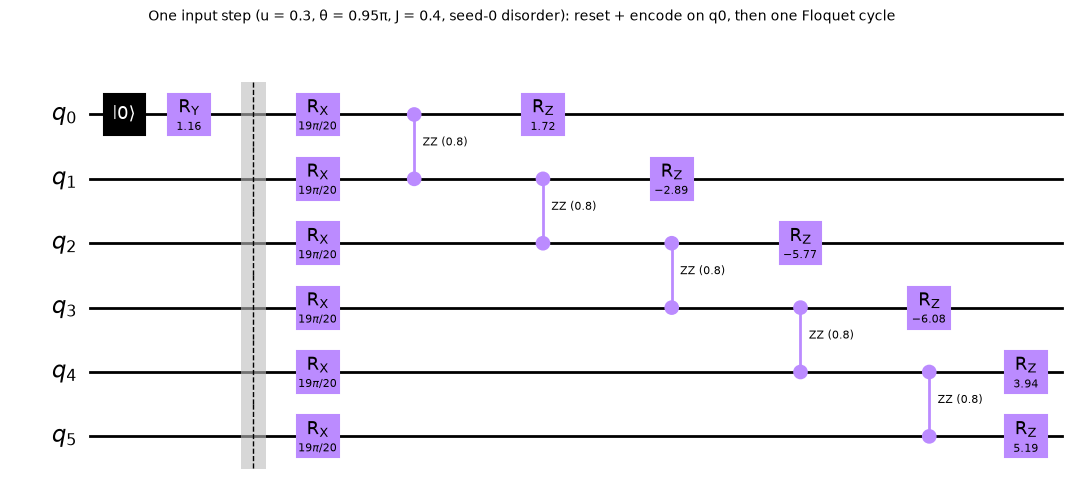

[classical simulation — no quantum hardware used]  depth=9, ops={'rx': 6, 'rz': 6, 'rzz': 5, 'reset': 1, 'ry': 1, 'barrier': 1}


In [3]:
r_draw = FloquetReservoir(n=6, theta=0.95 * np.pi, J=0.4, seed=0)
qc_step = step_circuit(n=6, u=0.3, theta=r_draw.theta, J=r_draw.J, h=r_draw.h, cycles=1)
fig = qc_step.draw("mpl", fold=-1, style="clifford")
fig.suptitle("One input step (u = 0.3, θ = 0.95π, J = 0.4, seed-0 disorder): reset + encode on q0, then one Floquet cycle", fontsize=10)
display(fig); plt.close(fig)
print(f"[{LABEL}]  depth={qc_step.depth()}, ops={dict(qc_step.count_ops())}")

## 3. Cross-check: NumPy reservoir vs Qiskit Aer

The experiments use a fast NumPy density-matrix implementation. To show that it is the same model as the circuit above,
we run 3 input steps on $n = 3$ qubits both ways and compare all features. The Qiskit side is the circuit from
`step_circuit`, with `save_density_matrix` after each step, run on `AerSimulator(method="density_matrix")`.
This mirrors `tests/test_reservoir.py::test_matches_qiskit_aer_density_matrix`.

In [4]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

n_chk, u_chk = 3, [0.2, 0.9, 0.55]
r_chk = FloquetReservoir(n=n_chk, theta=0.7 * np.pi, J=0.4, cycles_per_step=2, seed=5)
F_np = r_chk.run(np.array(u_chk))

qc = QuantumCircuit(n_chk)
for t, x in enumerate(u_chk):
    step_circuit(n_chk, x, r_chk.theta, r_chk.J, r_chk.h, 2, qc)
    qc.save_density_matrix(label=f"s{t}")
res = AerSimulator(method="density_matrix").run(qc).result().data(0)
F_aer = np.array([r_chk.features_from_probs(np.real(np.diag(np.asarray(res[f"s{t}"])))) for t in range(len(u_chk))])

cols = [f"<Z{i}>" for i in range(n_chk)] + [f"<Z{i}Z{i+1}>" for i in range(n_chk - 1)]
display(pd.DataFrame(np.vstack([F_np, F_aer]), columns=cols,
                     index=[f"NumPy t={t}" for t in range(3)] + [f"Aer t={t}" for t in range(3)]))
print(f"[{LABEL}]  max |NumPy - Aer| feature difference = {np.abs(F_np - F_aer).max():.2e}")

,<Z0>,<Z1>,<Z2>,<Z0Z1>,<Z1Z2>
NumPy t=0,0.446,0.735,-0.155,0.420,-0.193
NumPy t=1,-0.757,0.166,0.076,-0.029,0.401
NumPy t=2,-0.220,0.332,0.602,0.080,0.457
Aer t=0,0.446,0.735,-0.155,0.420,-0.193
Aer t=1,-0.757,0.166,0.076,-0.029,0.401
Aer t=2,-0.220,0.332,0.602,0.080,0.457


[classical simulation — no quantum hardware used]  max |NumPy - Aer| feature difference = 3.89e-16


## 4. Live mini-demo

### 4a. Time-crystal signature

With no input, start from all spins up, apply $U_F$ repeatedly to the 64-dimensional state vector, and record the mean
magnetisation $m_z(t) = \frac1N\sum_i\langle Z_i\rangle$.

- **θ = 0.95π, J = 0.4:** $m_z$ keeps flipping sign every cycle with nearly full amplitude, even though each kick
  misses π by 5 %. This is period doubling, the DTC.
- **θ = 0.95π, J = 0:** the same imperfect kick without interactions. The per-spin errors accumulate and the clean
  ±1 pattern dephases.
- **θ = 0.5π, J = 0.4:** scrambling. The magnetisation decays quickly to ≈ 0.

θ = 0.95π, J = 0.4 (time crystal)        period-doubling order over cycles 21-40: +0.980
θ = 0.95π, J = 0 (no interactions)       period-doubling order over cycles 21-40: -0.119
θ = 0.5π, J = 0.4 (scrambling)           period-doubling order over cycles 21-40: -0.003


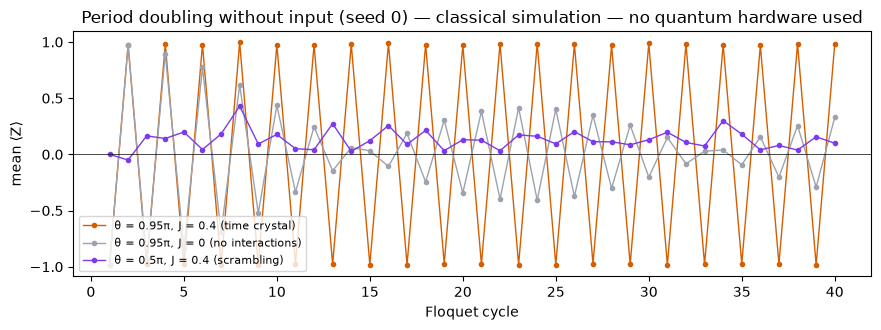

In [5]:
def magnetisation(theta, J, seed=0, cycles=40):
    r = FloquetReservoir(n=6, theta=theta, J=J, seed=seed)
    psi = np.zeros(2**r.n, dtype=complex); psi[0] = 1.0   # all spins up
    mz = []
    for _ in range(cycles):
        psi = r.U @ psi
        mz.append(float(np.abs(psi) ** 2 @ r.z.mean(axis=1)))
    return np.array(mz)

cyc = np.arange(1, 41)
cases = {"θ = 0.95π, J = 0.4 (time crystal)": (0.95 * np.pi, 0.4, "#d55e00"),
         "θ = 0.95π, J = 0 (no interactions)": (0.95 * np.pi, 0.0, "#9ca3af"),
         "θ = 0.5π, J = 0.4 (scrambling)": (0.5 * np.pi, 0.4, "#7c3aed")}
fig, ax = plt.subplots(figsize=(9, 3.4))
for lab, (th, J, c) in cases.items():
    mz = magnetisation(th, J)
    ax.plot(cyc, mz, "o-", ms=3, lw=1, color=c, label=lab)
    order = np.mean([(-1) ** t * v for t, v in zip(cyc[20:], mz[20:])])
    print(f"{lab:40s} period-doubling order over cycles 21-40: {order:+.3f}")
ax.axhline(0, color="k", lw=0.5)
ax.set(xlabel="Floquet cycle", ylabel="mean ⟨Z⟩", title=f"Period doubling without input (seed 0) — {LABEL}")
ax.legend(fontsize=8, loc="lower left"); plt.tight_layout(); plt.show()

### 4b. Memory capacity: scrambling vs time crystal vs ESN

1500 steps of iid uniform input. The first 200 steps are washout, the next 1000 train the readout, and the last 300
measure $r^2_k$ for delays $k = 0..15$. Three disorder seeds per model, with the same 11 features for all.

MC        QC (quadratic)       
                                 mean    std           mean    std
model                                                             
quantum θ=0.5π (scrambling)     4.689  1.305          3.269  1.620
quantum θ=0.95π (time crystal)  1.264  0.335          0.815  0.516
ESN, 11 nodes (ρ=0.9)           6.717  0.642          4.776  1.160

[classical simulation — no quantum hardware used]  computed live in 0.7 s


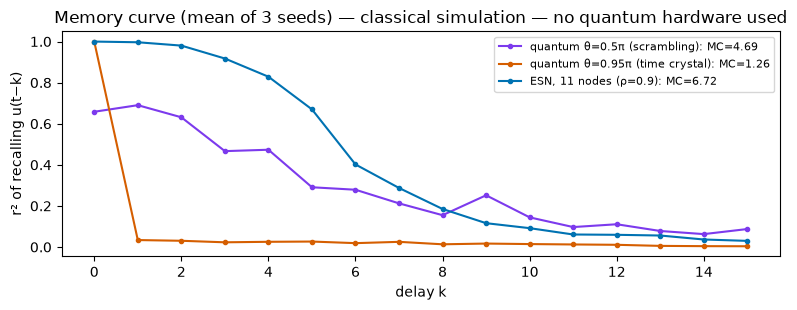

In [6]:
t0 = time.time()
rows, curves = [], {}
models = {"quantum θ=0.5π (scrambling)": lambda u, s: FloquetReservoir(n=6, theta=0.5 * np.pi, J=0.4, seed=s).run(u),
          "quantum θ=0.95π (time crystal)": lambda u, s: FloquetReservoir(n=6, theta=0.95 * np.pi, J=0.4, seed=s).run(u),
          "ESN, 11 nodes (ρ=0.9)": lambda u, s: EchoStateNetwork(n_nodes=11, spectral_radius=0.9, seed=s).run(u)}
for name, f in models.items():
    lin = []
    for s in range(3):
        u = np.random.default_rng(100 + s).uniform(size=1500)
        c = capacities(f(u, s), u)
        rows.append({"model": name, "seed": s, "MC": c["MC"], "QC (quadratic)": c["QC"]})
        lin.append(c["linear_by_delay"])
    curves[name] = np.mean(lin, axis=0)
mc_demo = pd.DataFrame(rows)
display(mc_demo.groupby("model", sort=False)[["MC", "QC (quadratic)"]].agg(["mean", "std"]))
print(f"[{LABEL}]  computed live in {time.time() - t0:.1f} s")

fig, ax = plt.subplots(figsize=(8, 3.2))
for (name, cv), c in zip(curves.items(), ["#7c3aed", "#d55e00", "#0072b2"]):
    ax.plot(range(len(cv)), cv, "o-", ms=3, color=c, label=f"{name}: MC={cv.sum():.2f}")
ax.set(xlabel="delay k", ylabel="r² of recalling u(t−k)", title=f"Memory curve (mean of 3 seeds) — {LABEL}")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 5. Assumptions

| # | Assumption | Why / consequence |
|---|---|---|
| 1 | **6 spins** (64-dim Hilbert space, 11 readout features) | Exact density-matrix simulation is cheap. Small enough to match the classical models feature for feature. |
| 2 | **Exact expectations** $\langle Z_i\rangle, \langle Z_iZ_{i+1}\rangle$ unless a shot count is stated | This is the idealised upper bound. Section 6 (E3) measures what finite shots cost. |
| 3 | **iid uniform input** $u_t \sim \mathcal U(0,1)$ for memory capacity | The standard memory-capacity protocol (washout 200, train 1000, test 300, delays 0–15). |
| 4 | **Disorder** $h_i \sim \mathcal U(-\pi, \pi)$ ($W = \pi$), set by the seed | Strong disorder, the setting where a DTC is stable. A different seed gives a different reservoir. |
| 5 | **2 Floquet cycles per input step** | 1 cycle was also scanned in E1. The forecasting experiments use 2. |
| 6 | **Time-ordered split 65 / 15 / 20 %** (train / validation / test) | No shuffling and no look-ahead. The test block is the most recent 20 %. |
| 7 | **Scaling on train only** (min–max from the training block; not clipped — the quantum encoder clamps its input to [0, 1]) | No test-set statistics leak into the inputs. |
| 8 | **Validation-only tuning** | Ridge α, the quantum θ ∈ {0.2,…,0.95}π, the ESN spectral radius and input scale, and the AR order p ∈ 1..11 are all picked on validation. The model is then refit on train+val and tested once. |
| 9 | **11 matched features** | Quantum: 6 ⟨Z⟩ + 5 ⟨ZZ⟩. ESN: 11 tanh nodes. AR: up to 11 lags. Every model uses the same ridge readout with bias. |
| 10 | **8 seeds** for forecasting (5 for the memory scan and the noise study) | Each seed changes the disorder (quantum) or the random weights (ESN). We report medians and ranges. |
| 11 | **Diebold–Mariano test** (squared-error loss, horizon 1) per seed | Tests whether two models' test errors differ significantly (p < 0.05), not just whether their NMSE values differ. |
| 12 | **Synthetic depolarizing noise**, probability p per qubit per cycle | A generic, device-agnostic stand-in for hardware noise. It is not a calibrated model of any real device. |
| 13 | **Shots model:** features at each step are estimated from S bitstrings sampled from the exact distribution, without collapsing the simulated state | Equivalent to re-running the input sequence up to every readout time. That restart cost is counted in Section 7. |

Data: yearly sunspot number 1700–2008 (309 values) and the monthly change in Mauna Loa CO₂, 1958–2001 (525 values).
Both come bundled with `statsmodels`, so the data are small and offline.

## 6. Results (loaded from `artifacts/*.json` — classical simulation, no quantum hardware used)

### 6a. E1 — memory capacity vs kick angle θ (phase scan)

20 values of θ, 3 values of J, 1 or 2 cycles per step, and 5 seeds: 600 reservoirs. The "DTC order" column is the
period-doubling score of the same chain with no input (mean of $(-1)^t m_z(t)$ over cycles 21–40). Shown below:
2 cycles per step, mean over seeds.

In [7]:
d1 = pd.DataFrame([{k: v for k, v in r.items() if k != "linear_by_delay"} for r in e1["rows"]])
tab = d1[d1.cycles_per_step == 2].pivot_table(index="theta_over_pi", columns="J", values=["MC", "dtc_order"], aggfunc="mean")
tab.columns = [f"{v} (J={J:g})" for v, J in tab.columns]
print(f"E1 memory capacity, 6 spins, 2 cycles/step, mean of 5 seeds — {LABEL}")
display(tab.round(2))

esn_tab = pd.DataFrame(e1["esn"]).groupby("spectral_radius")[["MC", "QC"]].mean()
print("Classical baselines with 11 features:")
display(esn_tab.rename(index=lambda r: f"ESN ρ={r}").round(2))
print(f"11-lag linear buffer: MC = {e1['lags11']['MC']:.2f}, QC = {e1['lags11']['QC']:.2f}")
j4 = d1[(d1.cycles_per_step == 2) & (d1.J == 0.4)].groupby("theta_over_pi")["MC"].mean()
print(f"J=0.4: max MC {j4.max():.2f} at θ={j4.idxmax():.2f}π; at θ=0.95π MC={j4.loc[0.95]:.2f}; "
      f"J=0 control max over θ: {d1[(d1.cycles_per_step == 2) & (d1.J == 0)].groupby('theta_over_pi')['MC'].mean().max():.2f}")

E1 memory capacity, 6 spins, 2 cycles/step, mean of 5 seeds — classical simulation — no quantum hardware used


,MC (J=0),MC (J=0.4),MC (J=0.785),dtc_order (J=0),dtc_order (J=0.4),dtc_order (J=0.785)
theta_over_pi,,,,,,
0.05,1.04,1.26,1.11,-0.00,0.00,0.00
0.10,1.03,1.60,1.82,-0.00,-0.00,-0.00
0.15,1.03,2.10,2.55,0.00,0.00,0.00
0.20,0.96,2.99,3.58,-0.00,0.00,-0.00
0.25,0.57,3.93,4.59,0.00,0.00,0.00
0.30,0.62,4.47,5.06,-0.00,0.00,-0.00
0.35,0.72,5.11,5.07,0.00,0.00,0.01
0.40,0.78,5.65,4.70,0.00,0.00,0.01
0.45,0.76,5.75,4.13,-0.00,0.00,0.00


Classical baselines with 11 features:


,MC,QC
spectral_radius,,
ESN ρ=0.5,5.89,4.66
ESN ρ=0.9,7.16,5.44
ESN ρ=1.1,5.81,4.64


11-lag linear buffer: MC = 11.00, QC = 8.84
J=0.4: max MC 5.75 at θ=0.45π; at θ=0.95π MC=1.32; J=0 control max over θ: 1.07


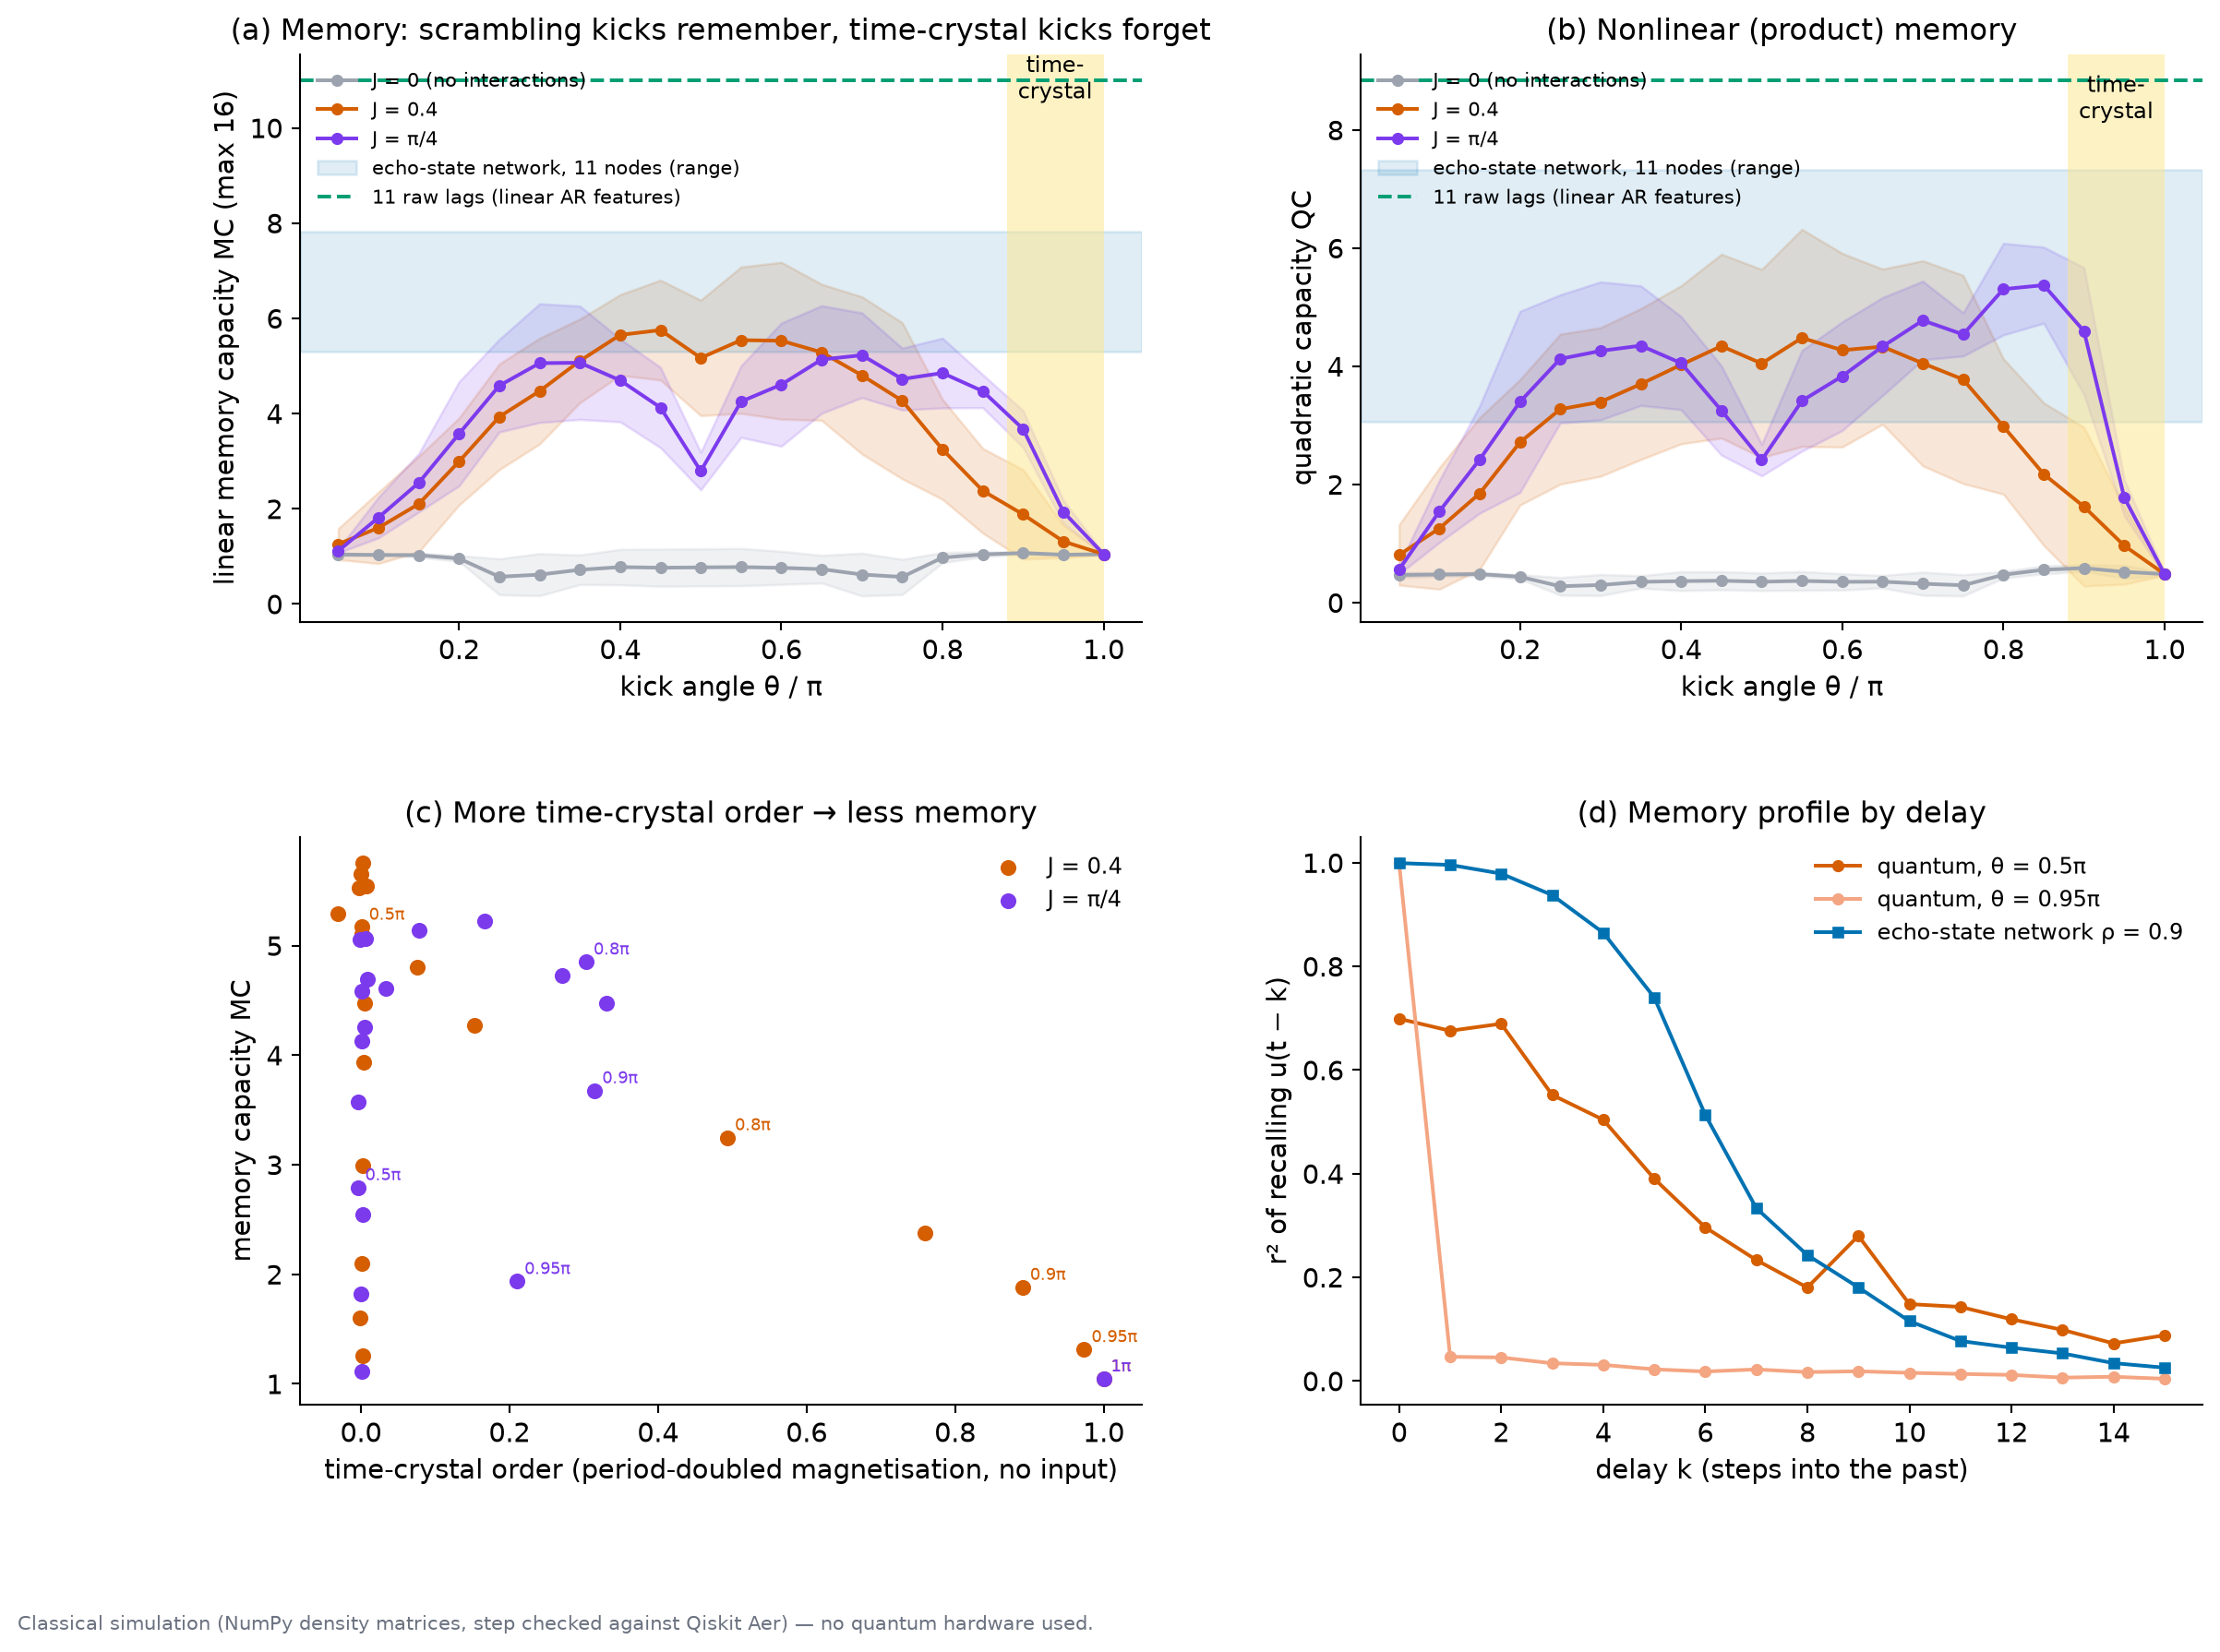

In [8]:
display(Image(filename=str(FIG / "phase_figure.png"), width=900))

**Reading E1.** Memory rises from the weak-kick regime to a broad maximum in the scrambling window, then falls as the
DTC order switches on near θ → π. At θ = 0.95π, where the DTC order is close to 1, the chain keeps little more than the
J = 0 control (this holds at J = 0.4, where the DTC order is close to 1). At θ = π the kick is perfect, the bulk never mixes, and memory collapses to remembering only the current
input. The dip at θ = 0.5π for J = π/4 is the special dual-unitary point of the kicked-Ising model. There the dynamics
is maximally scrambling. A plausible reading is that information spreads beyond what a 6-site local readout can
recover, but we did not test this.

### 6b. E2 — one-step forecasting on real data

Every model gets the same scaled series, the same 65/15/20 split, the same ridge readout, and at most 11 features.
Persistence ($\hat u_{t+1} = u_t$) is shown as a floor.

In [9]:
LABELS = {"quantum_reservoir": "Quantum reservoir (J=0.4, θ tuned on val)",
          "quantum_reservoir_J0": "Quantum reservoir, J=0 control",
          "esn": "ESN, 11 nodes (ρ, scale tuned on val)"}
for series in ("sunspots", "co2"):
    x = e2[series]
    rows = [{"model": f"Linear AR (p={x['ar']['p']}, tuned on val)", "median test NMSE": x["ar"]["test_nmse"],
             "min": x["ar"]["test_nmse"], "max": x["ar"]["test_nmse"], "seeds": 1, "AR signif. better (DM p<0.05)": "—"}]
    for m, lab in LABELS.items():
        R = [r for r in x["runs"] if r["model"] == m]
        v = np.array([r["test_nmse"] for r in R])
        rows.append({"model": lab, "median test NMSE": np.median(v), "min": v.min(), "max": v.max(), "seeds": len(v),
                     "AR signif. better (DM p<0.05)": f"{sum(r['dm_vs_ar']['p_value'] < 0.05 and r['dm_vs_ar']['mean_loss_diff'] > 0 for r in R)}/{len(R)}"})
    rows.append({"model": "Persistence (u_{t+1} = u_t)", "median test NMSE": x["persistence_test_nmse"],
                 "min": x["persistence_test_nmse"], "max": x["persistence_test_nmse"], "seeds": 1, "AR signif. better (DM p<0.05)": "—"})
    print(f"\n{x['description']} — test block {x['split']['test']}, {LABEL}")
    display(pd.DataFrame(rows).set_index("model").sort_values("median test NMSE"))


Yearly sunspot number 1700–2008 (309 values, statsmodels) — test block [247, 309], classical simulation — no quantum hardware used


,median test NMSE,min,max,seeds,AR signif. better (DM p<0.05)
model,,,,,
"Linear AR (p=10, tuned on val)",0.131,0.131,0.131,1,—
"ESN, 11 nodes (ρ, scale tuned on val)",0.167,0.148,0.421,8,1/8
"Quantum reservoir (J=0.4, θ tuned on val)",0.381,0.214,0.984,8,7/8
Persistence (u_{t+1} = u_t),0.391,0.391,0.391,1,—
"Quantum reservoir, J=0 control",0.425,0.356,0.918,8,8/8



Mauna Loa CO2, monthly change 1958–2001 (525 values, statsmodels) — test block [420, 525], classical simulation — no quantum hardware used


,median test NMSE,min,max,seeds,AR signif. better (DM p<0.05)
model,,,,,
"Linear AR (p=11, tuned on val)",0.112,0.112,0.112,1,—
"ESN, 11 nodes (ρ, scale tuned on val)",0.128,0.103,0.223,8,3/8
"Quantum reservoir (J=0.4, θ tuned on val)",0.205,0.149,0.300,8,7/8
"Quantum reservoir, J=0 control",0.493,0.363,0.549,8,8/8
Persistence (u_{t+1} = u_t),0.572,0.572,0.572,1,—


**Is the quantum reservoir better than its own J = 0 control?** We pair the runs by seed (same disorder fields, only
the coupling differs) and run a Diebold–Mariano test on the saved test predictions. We do the same against the ESN.

In [10]:
rows = []
for series in ("sunspots", "co2"):
    runs = e2[series]["runs"]
    by = lambda m: {r["seed"]: r for r in runs if r["model"] == m}
    q, q0, es = by("quantum_reservoir"), by("quantum_reservoir_J0"), by("esn")
    err = lambda r: np.array(r["true"]) - np.array(r["pred"])
    for other, lab in ((q0, "J=0 control"), (es, "ESN")):
        dms = [diebold_mariano(err(other[s]), err(q[s])) for s in sorted(q)]   # positive mean => quantum (J=0.4) better
        rows.append({"series": series, "quantum J=0.4 vs": lab,
                     "seeds quantum lower NMSE": f"{sum(q[s]['test_nmse'] < other[s]['test_nmse'] for s in q)}/{len(q)}",
                     "quantum signif. better (p<0.05)": sum(d["p_value"] < 0.05 and d["mean_loss_diff"] > 0 for d in dms),
                     "quantum signif. worse (p<0.05)": sum(d["p_value"] < 0.05 and d["mean_loss_diff"] < 0 for d in dms),
                     "median NMSE quantum": np.median([q[s]["test_nmse"] for s in q]),
                     "median NMSE other": np.median([other[s]["test_nmse"] for s in q])})
print(f"Paired-by-seed comparisons (8 seeds) — {LABEL}")
display(pd.DataFrame(rows).set_index(["series", "quantum J=0.4 vs"]))
chosen = {s: summary["forecast"][s]["quantum_reservoir"]["chosen_theta_over_pi"] for s in ("sunspots", "co2")}
print("θ/π chosen on validation per seed:", chosen)

Paired-by-seed comparisons (8 seeds) — classical simulation — no quantum hardware used


seeds quantum lower NMSE  \
series   quantum J=0.4 vs                            
sunspots J=0 control                           4/8   
         ESN                                   1/8   
co2      J=0 control                           8/8   
         ESN                                   1/8   

                           quantum signif. better (p<0.05)  \
series   quantum J=0.4 vs                                    
sunspots J=0 control                                     3   
         ESN                                             0   
co2      J=0 control                                     8   
         ESN                                             0   

                           quantum signif. worse (p<0.05)  \
series   quantum J=0.4 vs                                   
sunspots J=0 control                                    1   
         ESN                                            6   
co2      J=0 control                                    0   
         ESN                                            5   

                           median NMSE quantum  median NMSE other  
series   quantum J=0.4 vs                                          
sunspots J=0 control                     0.381              0.425  
         ESN                             0.381              0.167  
co2      J=0 control                     0.205              0.493  
         ESN                             0.205              0.128

θ/π chosen on validation per seed: {'sunspots': [0.5, 0.8, 0.65, 0.5, 0.65, 0.65, 0.65, 0.8], 'co2': [0.65, 0.8, 0.5, 0.65, 0.65, 0.35, 0.65, 0.35]}


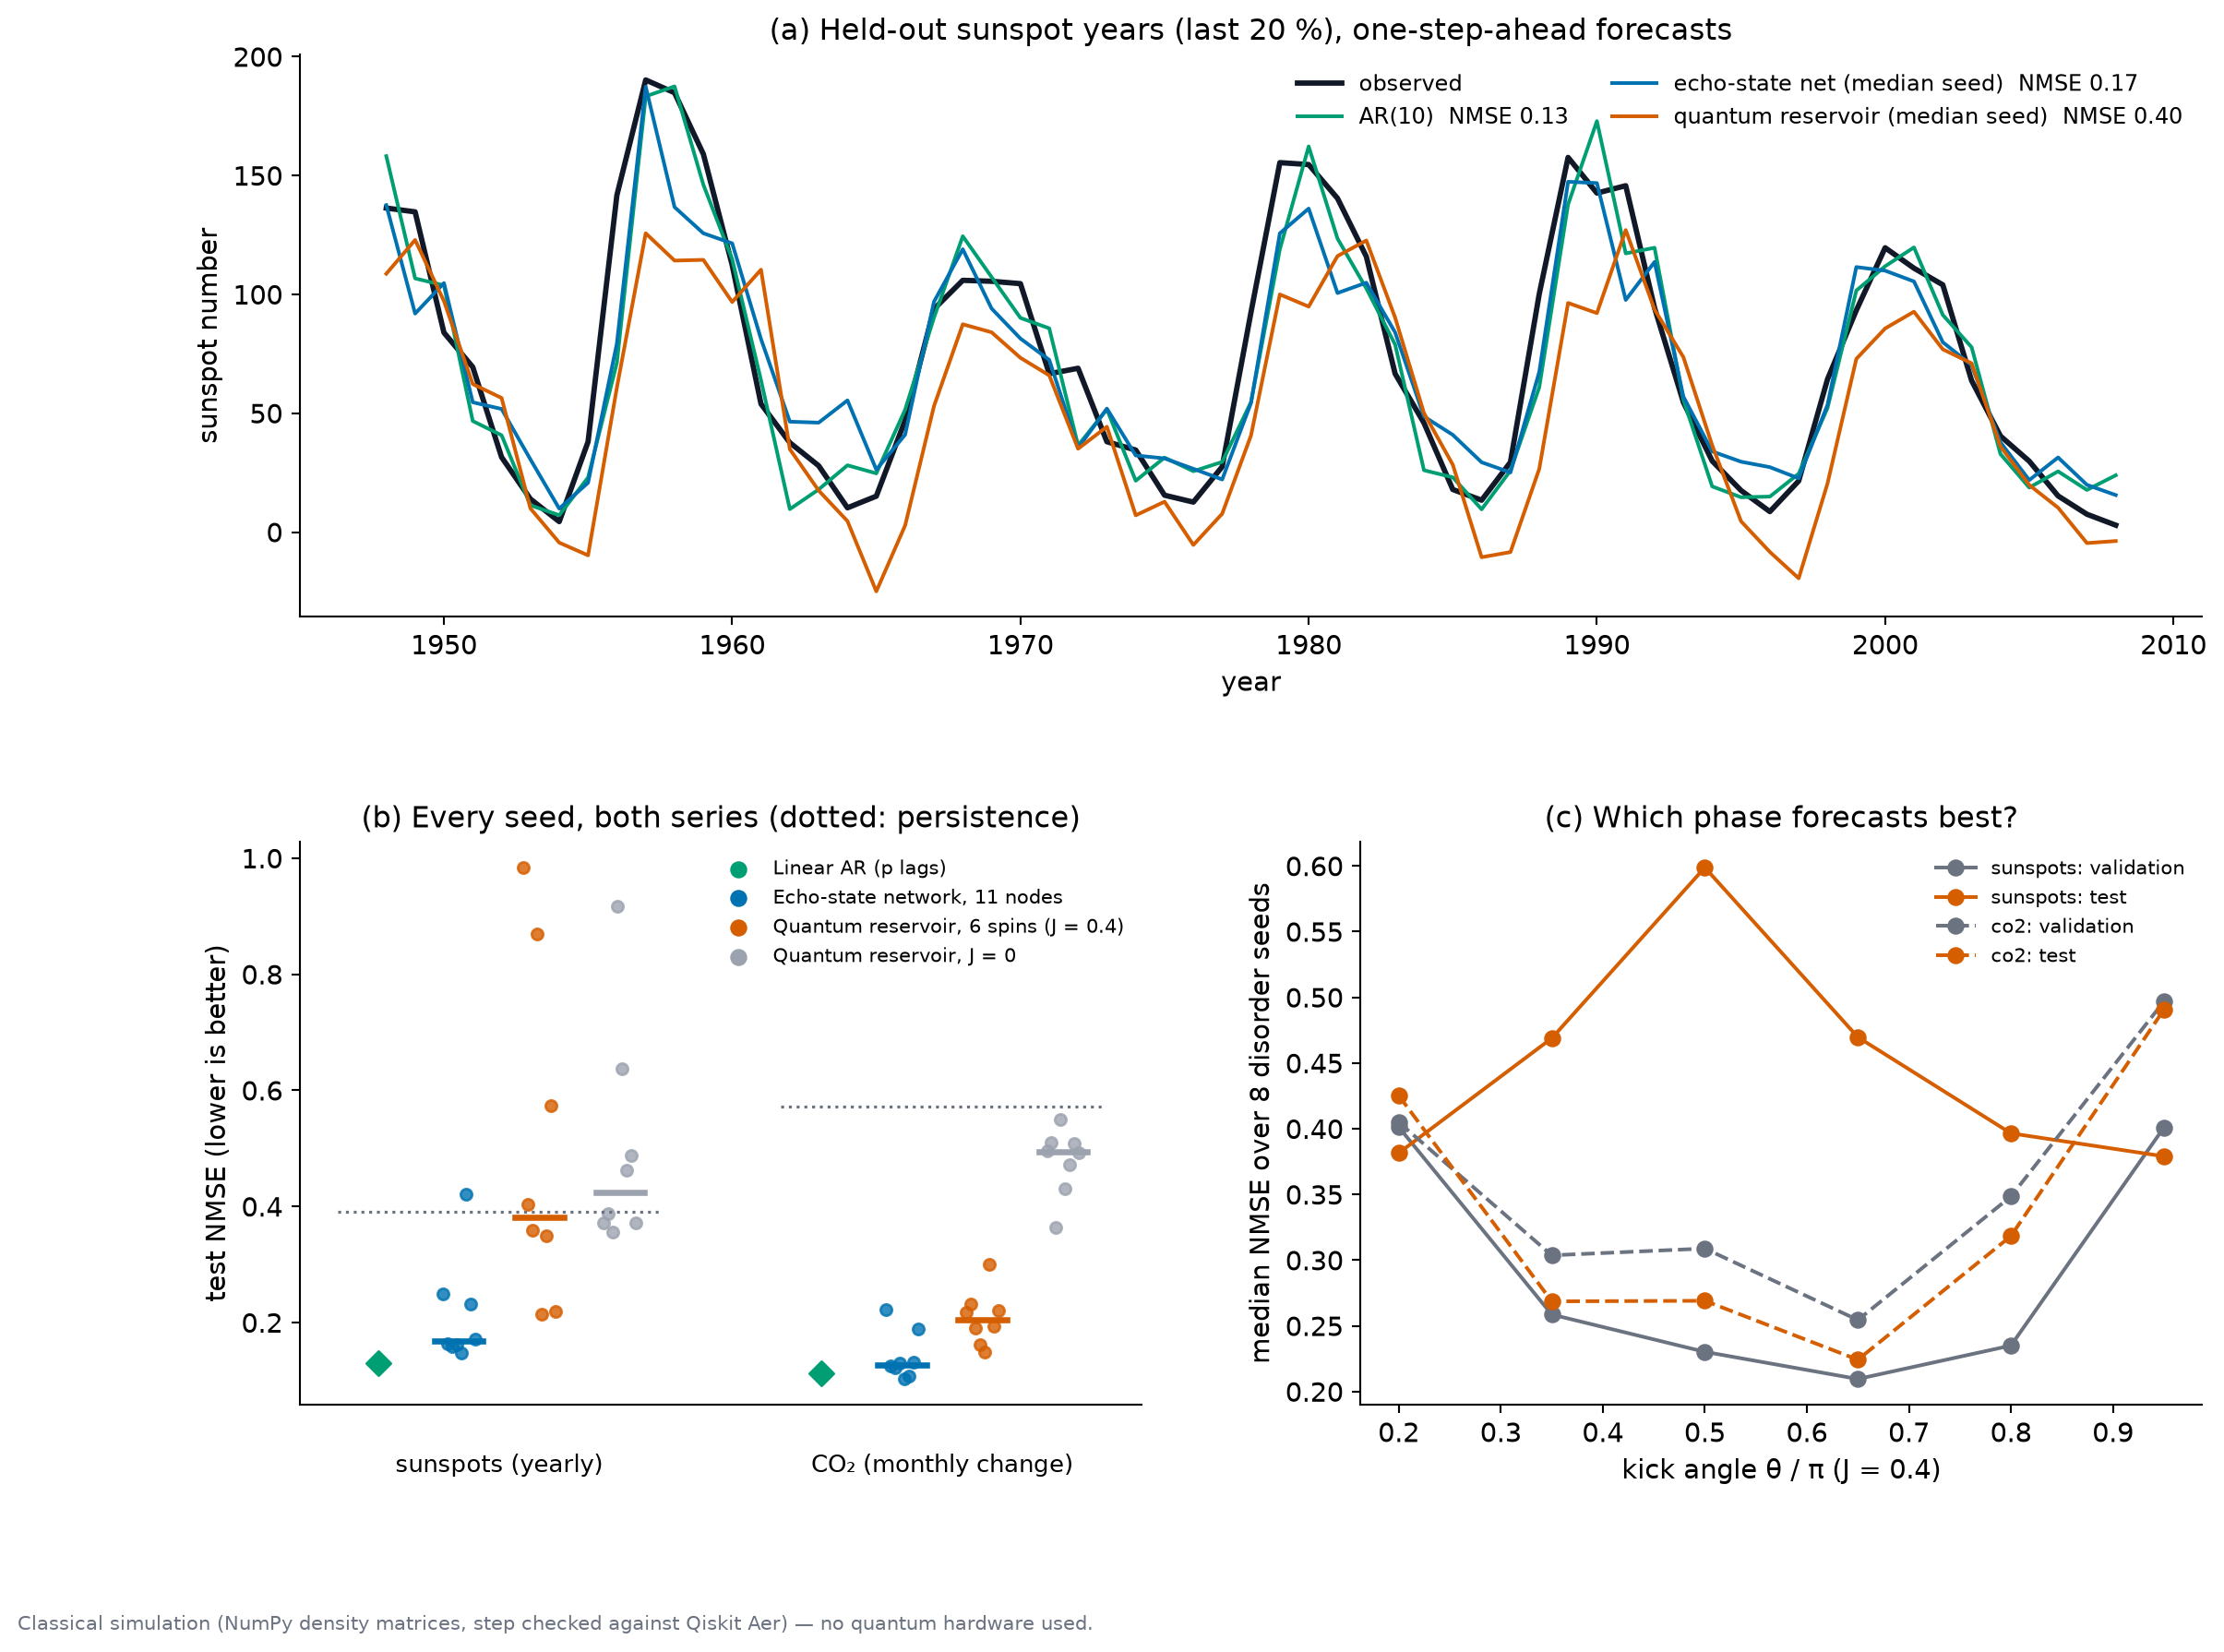

In [11]:
display(Image(filename=str(FIG / "forecast_figure.png"), width=900))

**Forecasting vs memory: does the phase ranking carry over?** Validation picks θ in the scrambling-to-intermediate
range (0.35–0.8π) for every seed, and never the time-crystal value 0.95π. The table below gives the
median test NMSE for each fixed θ. These test numbers were *not* used for selection and are shown only to diagnose
how well the selection worked. One caveat shows up: on sunspots, fixed θ = 0.95π has a low test NMSE even though it
was the worst on validation. That is a sign of how noisy a single 61-point sunspot test block is, and that NMSE is
still close to persistence. The rolling-origin evaluation below is the more reliable comparison.

In [12]:
th_tab = pd.DataFrame({s: summary["forecast"][s]["quantum_median_val_by_theta"] for s in ("sunspots", "co2")}).add_suffix(" val")
th_tab = th_tab.join(pd.DataFrame({s: summary["forecast"][s]["quantum_median_test_by_theta"] for s in ("sunspots", "co2")}).add_suffix(" test"))
th_tab.index.name = "θ/π"
print(f"Median NMSE over 8 seeds per fixed θ (J=0.4) — {LABEL}")
display(th_tab)

Median NMSE over 8 seeds per fixed θ (J=0.4) — classical simulation — no quantum hardware used


,sunspots val,co2 val,sunspots test,co2 test
θ/π,,,,
0.2,0.401,0.405,0.382,0.425
0.35,0.259,0.304,0.469,0.269
0.5,0.230,0.309,0.599,0.269
0.65,0.210,0.254,0.470,0.224
0.8,0.235,0.348,0.397,0.318
0.95,0.401,0.497,0.379,0.491


### 6c. Rolling-origin cross-validation

A single 65/15/20 split can be lucky or unlucky. The rolling-origin evaluation moves the forecast origin forward
through the series in four folds. Fold k trains on the first (50 + 10k) % of the series, validates on the next 10 %,
and tests on the 10 % after that, so the last fold tests on the final 10 %. Each fold repeats the full
tune-on-validation, test-once protocol. For each model we report the
median test NMSE across folds (each fold's value is the median over seeds), the mean rank across folds, and the
number of folds won.

In [13]:
ro = summary.get("rolling_origin")
if not ro:
    print("NOTE: summary.json has no 'rolling_origin' key yet — rolling-origin cross-validation was not run for this "
          "execution of the notebook. Results above use the single time-ordered 65/15/20 split only.")
else:
    print(f"Rolling-origin cross-validation — {LABEL}")
    for series, d in ro.items():
        folds = d.get("folds")
        nf = len(folds) if isinstance(folds, (list, tuple, dict)) else folds
        parts = {k: d[k] for k in ("median_test_nmse", "mean_rank", "wins") if isinstance(d.get(k), dict)}
        tab = pd.DataFrame(parts)
        tab.index.name = "model"
        if "mean_rank" in tab:
            tab = tab.sort_values("mean_rank")
        print(f"\n{series}: {nf} folds" + (f" (train end / val end / test end as fraction of series: {folds})"
                                           if isinstance(folds, list) else ""))
        display(tab)
        if isinstance(d.get("per_fold_median_test_nmse"), dict):
            pf = pd.DataFrame(d["per_fold_median_test_nmse"]).T
            pf.index = [f"fold {i}" for i in pf.index]
            print(f"{series}: median test NMSE over seeds, per fold")
            display(pf)

Rolling-origin cross-validation — classical simulation — no quantum hardware used

sunspots: 4 folds (train end / val end / test end as fraction of series: [[0.5, 0.6, 0.7], [0.6, 0.7, 0.8], [0.7, 0.8, 0.9], [0.8, 0.9, 1.0]])


,median_test_nmse,mean_rank,wins
model,,,
ar,0.158,1.25,3
esn,0.183,1.75,1
quantum_reservoir,0.262,3.50,0
persistence,0.410,4.00,0
quantum_reservoir_J0,0.424,4.50,0


sunspots: median test NMSE over seeds, per fold


,ar,persistence,esn,quantum_reservoir,quantum_reservoir_J0
fold 0,0.212,0.442,0.219,0.276,0.462
fold 1,0.178,0.506,0.172,0.248,0.531
fold 2,0.138,0.377,0.195,0.783,0.386
fold 3,0.103,0.355,0.104,0.217,0.339



co2: 4 folds (train end / val end / test end as fraction of series: [[0.5, 0.6, 0.7], [0.6, 0.7, 0.8], [0.7, 0.8, 0.9], [0.8, 0.9, 1.0]])


,median_test_nmse,mean_rank,wins
model,,,
ar,0.109,1.0,4
esn,0.155,2.0,0
quantum_reservoir,0.221,3.0,0
quantum_reservoir_J0,0.493,4.0,0
persistence,0.572,5.0,0


co2: median test NMSE over seeds, per fold


,ar,persistence,esn,quantum_reservoir,quantum_reservoir_J0
fold 0,0.124,0.585,0.165,0.251,0.499
fold 1,0.093,0.545,0.162,0.213,0.483
fold 2,0.091,0.558,0.103,0.176,0.487
fold 3,0.136,0.607,0.148,0.229,0.525


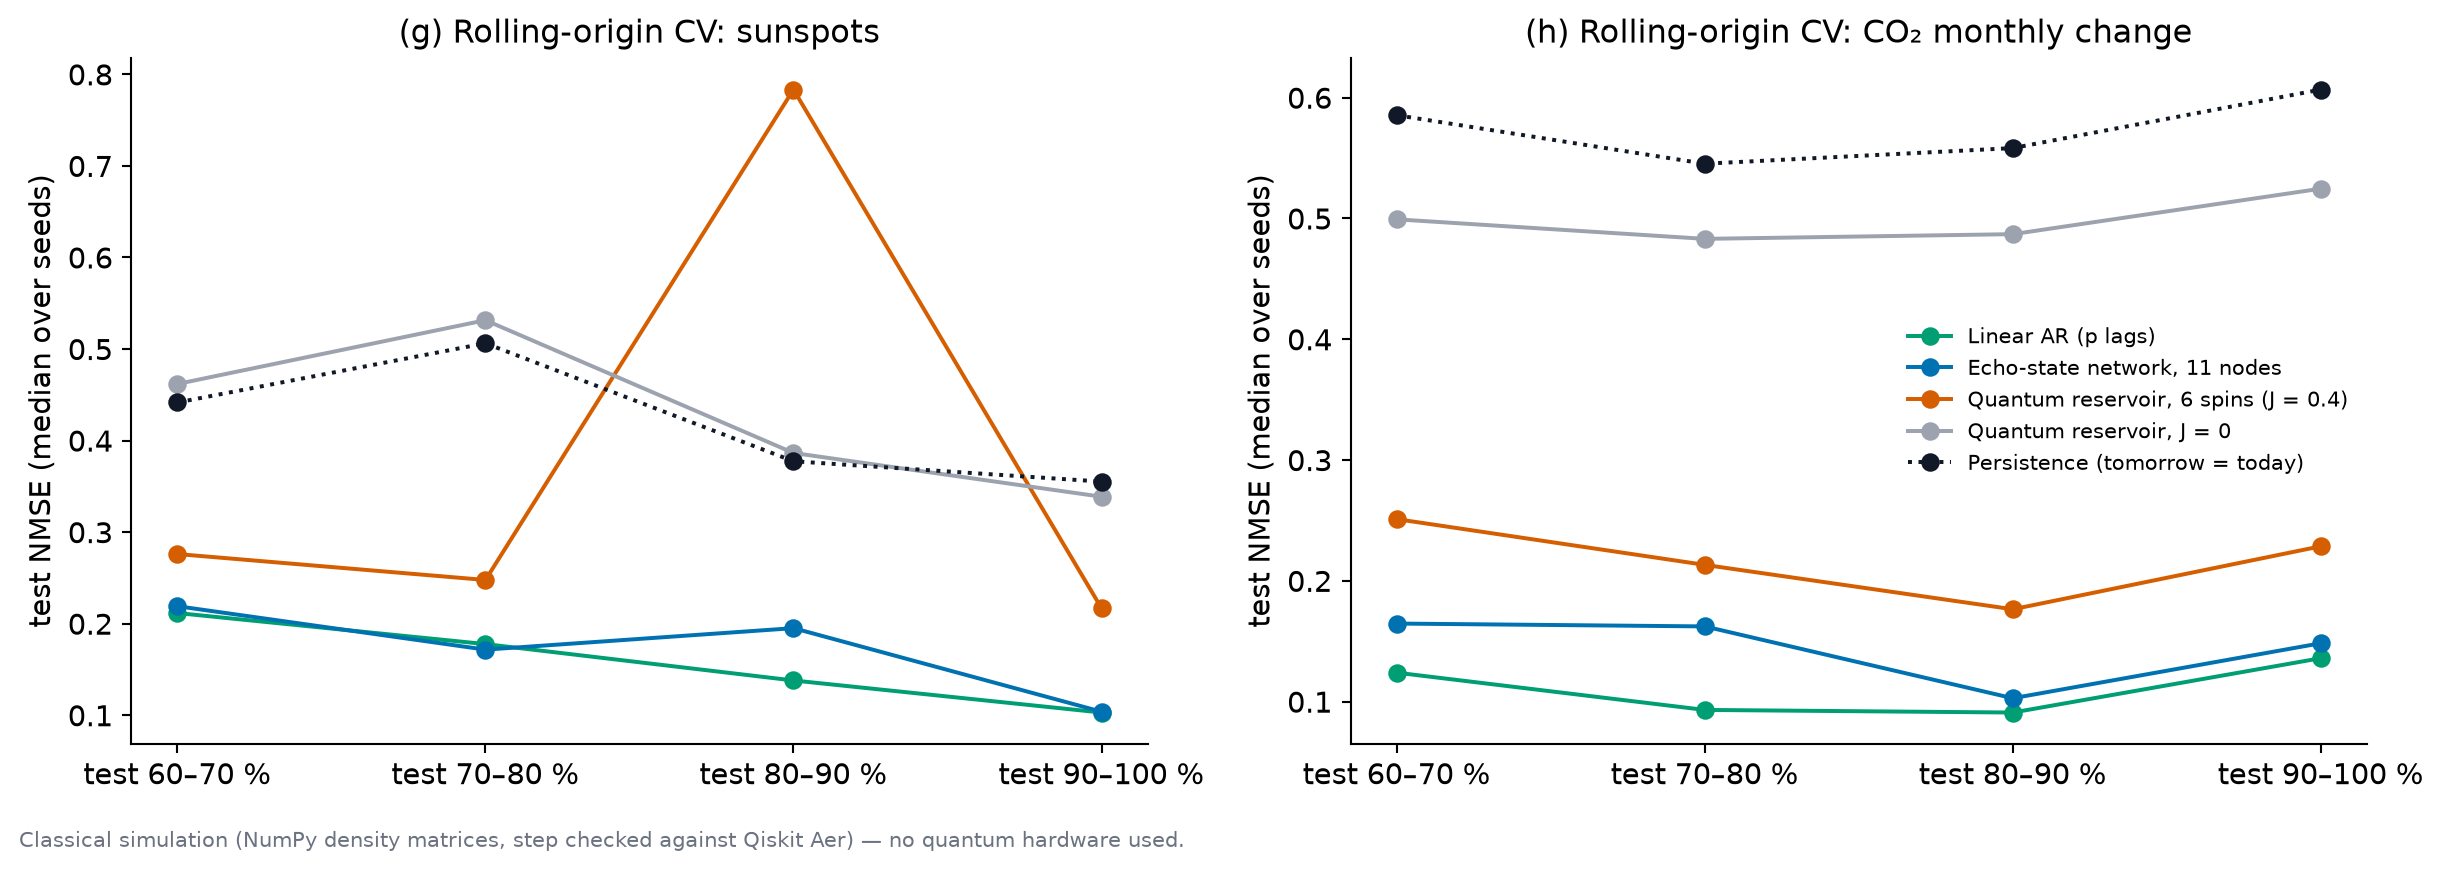

In [14]:
if summary.get("rolling_origin") and (FIG / "cv_figure.png").exists():
    display(Image(filename=str(FIG / "cv_figure.png"), width=900))
else:
    print("NOTE: figures/cv_figure.png not available — no rolling-origin figure to show.")

### 6d. E3 — shot noise and synthetic depolarizing noise (sunspots, 5 seeds)

For θ = 0.5π (scrambling) and θ = 0.95π (time crystal) we repeat the memory and sunspot tasks with features estimated
from a finite number of shots, and with depolarizing noise of probability p per qubit per cycle.

In [15]:
d3 = pd.DataFrame([{"θ/π": r["theta_over_pi"], "noise p": r["noise_p"], "shots": "exact" if r["shots"] is None else r["shots"],
                    "MC (mean)": np.mean(r["MC"]), "sunspot test NMSE (median)": np.median(r["sunspot_test_nmse"])}
                   for r in e3["rows"]])
print(f"E3 robustness (θ fixed, J=0.4, no θ re-tuning) — {LABEL}")
display(d3.set_index(["θ/π", "noise p", "shots"]))

E3 robustness (θ fixed, J=0.4, no θ re-tuning) — classical simulation — no quantum hardware used


MC (mean)  sunspot test NMSE (median)
θ/π  noise p shots                                       
0.50 0.000   exact      5.170                       0.489
             10000      4.266                       0.456
             1000       2.636                       0.436
             100        1.329                       0.486
     0.001   exact      5.240                       0.484
             1000       2.597                       0.437
     0.010   exact      5.604                       0.472
             1000       2.221                       0.465
     0.030   exact      5.843                       0.488
             1000       1.772                       0.430
0.95 0.000   exact      1.315                       0.368
             10000      1.059                       0.368
             1000       1.039                       0.372
             100        1.031                       0.381
     0.001   exact      1.255                       0.368
             1000       1.048                       0.360
     0.010   exact      1.891                       0.361
             1000       1.065                       0.365
     0.030   exact      2.123                       0.371
             1000       1.046                       0.378

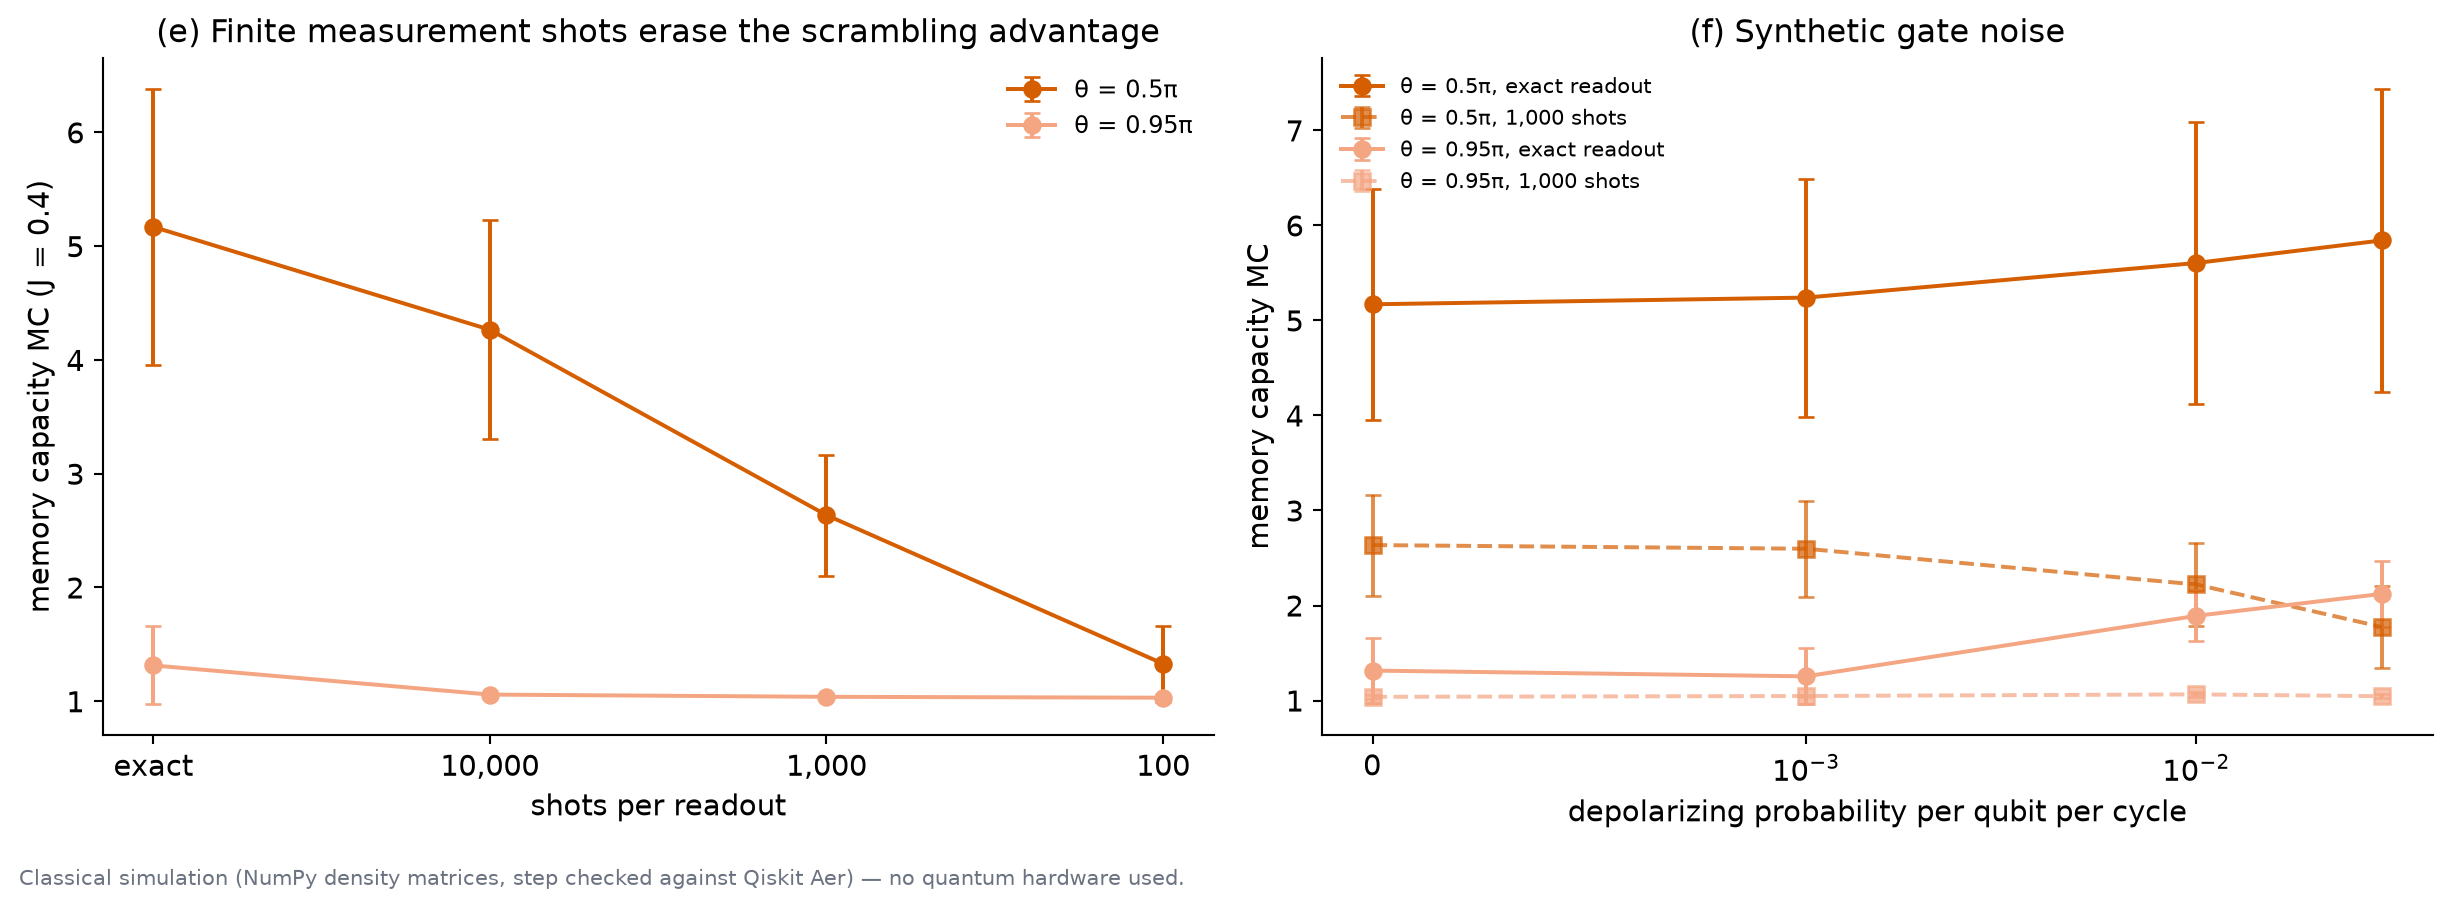

In [16]:
display(Image(filename=str(FIG / "robustness_figure.png"), width=900))

**Reading E3.** Finite shots remove most of the scrambling regime's memory advantage. The time-crystal setting has
little memory to lose in the first place. Two smaller effects are worth noting. First, with exact expectations,
mild depolarizing noise slightly *increases* memory capacity. Dissipation gives the reservoir a fading memory, in
line with Kubota et al. 2022. Second, the sunspot NMSE barely changes with shots or noise at either θ. On this series
the reservoir's forecast is limited by its features, not by how precisely they are estimated.

## 7. Where the classical model wins, and why

1. **Linear AR wins on both real series.** Yearly sunspots and seasonal CO₂ changes are close to linear,
   quasi-periodic signals. A linear combination of the last p values (an AR model) has exactly the right inductive bias
   for them. It is the classical Yule (1927) sunspot model. Neither reservoir can add useful nonlinearity, and both
   have to *reconstruct* the lags through a lossy, mixed state, which AR reads directly.
2. **The ESN beats the quantum reservoir with the same feature count.** With 11 features each, the tanh ESN keeps the
   recent inputs more cleanly than the 6-spin chain, where qubit 0 is overwritten every step and information
   leaks only through the ZZ couplings. Their memory capacities are similar (Section 6a), but on the real series the
   ESN's features are clearly more usable for forecasting.
3. **Shots cost.** The quantum memory advantage of the scrambling regime is measured with exact expectations. With
   realistic shot counts the scrambling memory shrinks a lot, and by 100 shots it is close to the time-crystal level. The ESN and AR have no such cost.
4. **Restart cost.** On hardware, reading out ⟨Z⟩ destroys the state. Getting features at every step therefore means
   re-running the input sequence up to each readout time. That cost is quadratic in the series length, while a
   classical model costs one pass.

In [17]:
print(f"[{LABEL}]")
for s, d in summary["forecast"].items():
    q, es = d["quantum_reservoir"], d["esn"]
    print(f"{s}: AR NMSE {d['ar_test_nmse']:.3f} vs ESN median {es['median_test_nmse']:.3f} vs quantum median {q['median_test_nmse']:.3f}"
          f"  -> quantum/AR = {q['median_test_nmse'] / d['ar_test_nmse']:.2f}x;"
          f" AR significantly better than quantum on {q['seeds_where_AR_significantly_better_p05']}/{q['n_seeds']} seeds,"
          f" ESN significantly better on {q['seeds_where_ESN_significantly_better_p05']}/{q['n_seeds']};"
          f" quantum seeds beating AR: {q['seeds_beating_AR']}")
sm = summary["shots_MC"]
for th in sm:
    print(f"θ={th}π memory capacity: exact {sm[th]['exact']:.2f} -> 1000 shots {sm[th]['1000']:.2f} -> 100 shots {sm[th]['100']:.2f}")
hc = summary["hardware_cost"]
print(f"Hardware restart cost for one sunspot pass (309 steps, 2 cycles/step): {hc['cycles_total_per_shot_sweep']:,} Floquet cycles per shot sweep;"
      f" {hc['circuit_runs_at_1000_shots']:,} circuit executions at 1000 shots per readout.")
print(f"  ({hc['note']})")

[classical simulation — no quantum hardware used]
sunspots: AR NMSE 0.131 vs ESN median 0.167 vs quantum median 0.381  -> quantum/AR = 2.92x; AR significantly better than quantum on 7/8 seeds, ESN significantly better on 6/8; quantum seeds beating AR: 0
co2: AR NMSE 0.112 vs ESN median 0.128 vs quantum median 0.205  -> quantum/AR = 1.83x; AR significantly better than quantum on 7/8 seeds, ESN significantly better on 5/8; quantum seeds beating AR: 0
θ=0.5π memory capacity: exact 5.17 -> 1000 shots 2.64 -> 100 shots 1.33
θ=0.95π memory capacity: exact 1.32 -> 1000 shots 1.04 -> 100 shots 1.03
Hardware restart cost for one sunspot pass (309 steps, 2 cycles/step): 95,790 Floquet cycles per shot sweep; 309,000 circuit executions at 1000 shots per readout.
  (Reading out every step on hardware destroys the state, so the sequence is re-run up to each readout time.)


## 8. Prior work and what is new here

Full notes are in `docs/literature.md`, from a quick hackathon-scale scan. It is not exhaustive.

- **Fujii & Nakajima, PR Applied 8, 024030 (2017)** introduced quantum reservoir computing (QRC). Our reset-qubit
  input injection comes from this paper.
- **Martínez-Peña et al., PRL 127, 100502 (2021)** and **Xia et al., Front. Phys. 17, 33506 (2022)** showed, for static
  disordered Hamiltonians, that the dynamical phase (MBL vs thermal) controls QRC performance, with the best
  performance near the transition.
- **Zhang et al., arXiv:2508.15230 (2025)** is the closest prior work, and its model is essentially ours: an imperfectly
  π-kicked disordered Ising chain with reset injection and ⟨Z⟩/⟨ZZ⟩ readout. They map short-term memory, parity and
  NARMA10 across the MBL, thermal and DTC phases, and run classification on superconducting hardware. **The DTC
  reservoir is therefore not our idea.** Their benchmarks are synthetic (NARMA10, MNIST), and they use no ESN or AR
  baseline.
- **Mujal et al., npj QI 9, 16 (2023)** quantified measurement and restart cost in time-series QRC.

**What this entry adds** (as an extension and replication of Zhang et al., not a first):
1. **Real-world time series** (sunspots and CO₂) instead of synthetic tasks only.
2. **Matched classical baselines**: an ESN with the same 11 features and the same readout, linear AR, and persistence.
   All share identical time-ordered splits, train-only scaling, validation-only tuning, and Diebold–Mariano tests.
   The quantum reservoir is also compared with its own J = 0 control.
3. **Forecasting vs memory phase choice**: the regime with the most memory and the regime chosen for forecasting are
   both on the scrambling side, while the DTC is worst for memory.
4. **Measurement cost**: what finite shots and the per-step restart protocol do to the memory advantage.

## 9. Limitations

- **Classical simulation only, no quantum hardware used.** The noise is a synthetic depolarizing channel, not a model
  of any real device. There is no crosstalk, readout error, leakage, or drift.
- **6 spins only.** A larger chain would give more features, and the comparison could change. Our conclusions are
  about matched feature budgets at this size. We did not show how the results scale.
- **Small datasets.** 309 sunspot years and 525 CO₂ months give test blocks of 61 and 104 points. DM tests on such
  blocks have limited power, and the single-split results depend on where the split falls. Section 6c addresses this
  when rolling-origin results are available.
- **Limited hyperparameter grids.** θ uses 6 values at a fixed J = 0.4 and 2 cycles, the ESN gets a 3 × 3 grid, and AR
  gets p = 1..11. A broader search (J, cycles, the input encoding, or a leaky ESN) could move all models.
- **One-step-ahead only.** Multi-step or free-running forecasts were not tested.
- **The shots model is optimistic about state reuse**: it samples from the exact distribution without collapsing the
  simulated state. That corresponds to re-running the sequence for every readout, at the cost given in Section 7.
  We did not simulate weak-measurement or windowed-replay protocols (Mujal et al.).
- **Memory capacity uses iid uniform input**, which is a standard but idealised probe. Real series are strongly
  autocorrelated, and that is why AR does so well on them.
- **The literature scan was short** (about 12 minutes), so related Floquet-QRC work may have been missed.

In [18]:
print(f"Notebook live cells finished in {time.time() - T0:.1f} s — {LABEL}.")
print("Artifact provenance:", {k: e2["provenance"][k] for k in ("created_utc", "python", "qiskit", "numpy")})

Notebook live cells finished in 1.2 s — classical simulation — no quantum hardware used.
Artifact provenance: {'created_utc': '2026-10-25T13:23:48Z', 'python': '3.12.13', 'qiskit': '2.6.0', 'numpy': '2.5.4'}
